# Homework 7.2 - Task 5

## Measure the Conditioning Effect

The central question is not whether one conditioned sentence looks different.

The question is whether conditioning changes the generated distribution in a measurable and reproducible way.

For each theme, this notebook compares 500 unconditioned and 500 conditioned draws.

## Metrics

The following metrics are reported separately.

### Rewarded word rate

This is expected to increase because the conditioning rule directly rewards those words.

### Unboosted thematic probe rate

These words receive no direct probability boost.

A change in this rate is more informative than a change in the explicitly rewarded words, although it is still only a lexical diagnostic.

### Sentence length

Conditioning may alter how quickly the model emits the sentence-end marker.

### Truncation rate

A sentence is truncated if generation reaches the 30-word limit before the end marker.

### Internal repeated-bigram fraction

This measures simple repetition within a generated sentence.

### Odyssey bigram coverage

This is the fraction of adjacent generated word pairs that occur somewhere in the Odyssey target corpus.

### Jensen-Shannon distance

This compares the overall conditioned and unconditioned unigram distributions for each theme.

In [1]:
from pathlib import Path
from collections import Counter
import json
import math
import pickle
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import jensenshannon

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw7_2"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw7_2"

generations = pd.read_csv(
    DATA_DIR
    / "task3_statistical_generations.csv"
)

design = json.loads(
    (
        DATA_DIR
        / "task1_fixed_experiment_design.json"
    ).read_text(
        encoding="utf-8"
    )
)

with open(
    DATA_DIR
    / "task2_odyssey_ngram_model.pkl",
    "rb",
) as handle:
    model = pickle.load(
        handle
    )

THEMES = design[
    "themes"
]

rewarded_words = model[
    "rewarded_words_in_vocab"
]

probe_words = model[
    "probe_words_in_vocab"
]

bigram_model = model[
    "bigram"
]

vocabulary = [
    word
    for word
    in model[
        "vocabulary"
    ]
    if word != "</s>"
]

vocabulary_index = {
    word: index
    for index, word
    in enumerate(vocabulary)
}

BOOTSTRAP_SEED = 63875
BOOTSTRAP_REPLICATES = 2000

print(
    generations.groupby(
        [
            "theme",
            "mode",
        ]
    ).size()
)

theme         mode         
anger         conditioned      500
              unconditioned    500
discipline    conditioned      500
              unconditioned    500
duty          conditioned      500
              unconditioned    500
mortality     conditioned      500
              unconditioned    500
self-command  conditioned      500
              unconditioned    500
dtype: int64


In [2]:
def tokenize_generated(text):
    return re.findall(
        r"[A-Za-z]+(?:'[A-Za-z]+)?",
        str(text).lower(),
    )


def repeated_bigram_fraction(tokens):
    if len(tokens) < 2:
        return 0.0

    bigrams = list(
        zip(
            tokens[:-1],
            tokens[1:],
        )
    )

    unique = len(
        set(bigrams)
    )

    return (
        1.0
        - unique / len(bigrams)
    )


def odyssey_bigram_coverage(tokens):
    if len(tokens) < 2:
        return 1.0

    pairs = list(
        zip(
            tokens[:-1],
            tokens[1:],
        )
    )

    observed = sum(
        second
        in bigram_model.get(
            first,
            {}
        )
        for first, second
        in pairs
    )

    return observed / len(
        pairs
    )


metric_rows = []

for row in generations.itertuples():
    tokens = tokenize_generated(
        row.text
    )

    metric_rows.append({
        "theme": row.theme,
        "mode": row.mode,
        "sample_index": (
            int(
                row.sample_index
            )
        ),
        "seed": int(
            row.seed
        ),
        "length": len(
            tokens
        ),
        "truncated": bool(
            row.truncated
        ),
        "reward_rate_per_100_words": float(
            row.reward_rate_per_100_words
        ),
        "probe_rate_per_100_words": float(
            row.probe_rate_per_100_words
        ),
        "repeated_bigram_fraction": (
            repeated_bigram_fraction(
                tokens
            )
        ),
        "odyssey_bigram_coverage": (
            odyssey_bigram_coverage(
                tokens
            )
        ),
    })


metrics = pd.DataFrame(
    metric_rows
)

metric_path = (
    DATA_DIR
    / "task5_per_sentence_metrics.csv"
)

metrics.to_csv(
    metric_path,
    index=False,
)

## Bootstrap difference in means

Let $m_c$ be the sample mean for conditioned outputs and $m_u$ the sample mean for unconditioned outputs. Define

$$
D = m_c - m_u.
$$

A fixed-seed nonparametric bootstrap with 2000 resamples gives a 95 percent interval for $D$.

In [3]:
def bootstrap_difference(
    conditioned_values,
    unconditioned_values,
    rng,
    replicates,
):
    conditioned_values = np.asarray(
        conditioned_values,
        dtype=float,
    )

    unconditioned_values = np.asarray(
        unconditioned_values,
        dtype=float,
    )

    observed = (
        conditioned_values.mean()
        - unconditioned_values.mean()
    )

    bootstrap = np.empty(
        replicates,
        dtype=float,
    )

    for b in range(
        replicates
    ):
        cond_sample = rng.choice(
            conditioned_values,
            size=len(
                conditioned_values
            ),
            replace=True,
        )

        uncond_sample = rng.choice(
            unconditioned_values,
            size=len(
                unconditioned_values
            ),
            replace=True,
        )

        bootstrap[b] = (
            cond_sample.mean()
            - uncond_sample.mean()
        )

    low, high = np.quantile(
        bootstrap,
        [
            0.025,
            0.975,
        ],
    )

    return (
        float(observed),
        float(low),
        float(high),
    )


summary_rows = []

for theme_index, theme in enumerate(
    THEMES
):
    conditioned = metrics[
        (
            metrics[
                "theme"
            ] == theme
        )
        & (
            metrics[
                "mode"
            ] == "conditioned"
        )
    ]

    unconditioned = metrics[
        (
            metrics[
                "theme"
            ] == theme
        )
        & (
            metrics[
                "mode"
            ] == "unconditioned"
        )
    ]

    rng = np.random.default_rng(
        BOOTSTRAP_SEED
        + theme_index
    )

    reward_diff = bootstrap_difference(
        conditioned[
            "reward_rate_per_100_words"
        ],
        unconditioned[
            "reward_rate_per_100_words"
        ],
        rng,
        BOOTSTRAP_REPLICATES,
    )

    probe_diff = bootstrap_difference(
        conditioned[
            "probe_rate_per_100_words"
        ],
        unconditioned[
            "probe_rate_per_100_words"
        ],
        rng,
        BOOTSTRAP_REPLICATES,
    )

    length_diff = bootstrap_difference(
        conditioned[
            "length"
        ],
        unconditioned[
            "length"
        ],
        rng,
        BOOTSTRAP_REPLICATES,
    )

    repeat_diff = bootstrap_difference(
        conditioned[
            "repeated_bigram_fraction"
        ],
        unconditioned[
            "repeated_bigram_fraction"
        ],
        rng,
        BOOTSTRAP_REPLICATES,
    )

    coverage_diff = bootstrap_difference(
        conditioned[
            "odyssey_bigram_coverage"
        ],
        unconditioned[
            "odyssey_bigram_coverage"
        ],
        rng,
        BOOTSTRAP_REPLICATES,
    )

    summary_rows.append({
        "theme": theme,
        "n_unconditioned": len(
            unconditioned
        ),
        "n_conditioned": len(
            conditioned
        ),
        "unconditioned_reward_rate": float(
            unconditioned[
                "reward_rate_per_100_words"
            ].mean()
        ),
        "conditioned_reward_rate": float(
            conditioned[
                "reward_rate_per_100_words"
            ].mean()
        ),
        "reward_rate_difference": (
            reward_diff[0]
        ),
        "reward_rate_ci_low": (
            reward_diff[1]
        ),
        "reward_rate_ci_high": (
            reward_diff[2]
        ),
        "unconditioned_probe_rate": float(
            unconditioned[
                "probe_rate_per_100_words"
            ].mean()
        ),
        "conditioned_probe_rate": float(
            conditioned[
                "probe_rate_per_100_words"
            ].mean()
        ),
        "probe_rate_difference": (
            probe_diff[0]
        ),
        "probe_rate_ci_low": (
            probe_diff[1]
        ),
        "probe_rate_ci_high": (
            probe_diff[2]
        ),
        "mean_length_difference": (
            length_diff[0]
        ),
        "repeat_fraction_difference": (
            repeat_diff[0]
        ),
        "bigram_coverage_difference": (
            coverage_diff[0]
        ),
        "unconditioned_truncation_rate": float(
            unconditioned[
                "truncated"
            ].mean()
        ),
        "conditioned_truncation_rate": float(
            conditioned[
                "truncated"
            ].mean()
        ),
    })


summary = pd.DataFrame(
    summary_rows
)

summary_path = (
    DATA_DIR
    / "task5_conditioning_metric_summary.csv"
)

summary.to_csv(
    summary_path,
    index=False,
)

print(
    summary.to_string(
        index=False
    )
)

       theme  n_unconditioned  n_conditioned  unconditioned_reward_rate  conditioned_reward_rate  reward_rate_difference  reward_rate_ci_low  reward_rate_ci_high  unconditioned_probe_rate  conditioned_probe_rate  probe_rate_difference  probe_rate_ci_low  probe_rate_ci_high  mean_length_difference  repeat_fraction_difference  bigram_coverage_difference  unconditioned_truncation_rate  conditioned_truncation_rate
  discipline              500            500                   0.013333                 0.090967                0.077634            0.020454             0.146127                  0.006667                0.006667               0.000000          -0.020000            0.020000                   0.772                    0.000439                    0.002969                          0.452                        0.486
   mortality              500            500                   0.143556                 0.486716                0.343161            0.142177             0.530107           

## Overall word-distribution change and a finite-sample baseline

For each theme, all generated words are pooled within each mode and a Jensen-Shannon distance is computed between the conditioned and unconditioned unigram distributions over the fixed Odyssey vocabulary.

A raw Jensen-Shannon distance cannot be interpreted by itself because the vocabulary is large and each empirical sample is finite. The unconditioned generator is identical for every theme, so pairwise distances between the five unconditioned theme groups provide an empirical null benchmark at the same sample size. If the conditioned-versus-unconditioned distance is no larger than this null range, the broad unigram distance is dominated by sampling variability rather than a detectable global lexical shift.

In [4]:
def pooled_word_distribution(
    frame,
):
    counts = np.zeros(
        len(vocabulary),
        dtype=float,
    )

    for text in frame[
        "text"
    ]:
        for word in tokenize_generated(
            text
        ):
            if word in vocabulary_index:
                counts[
                    vocabulary_index[
                        word
                    ]
                ] += 1

    if counts.sum() == 0:
        return counts

    return counts / counts.sum()


def js_distance(frame_a, frame_b):
    p = pooled_word_distribution(frame_a)
    q = pooled_word_distribution(frame_b)

    epsilon = 1e-12
    p = p + epsilon
    q = q + epsilon
    p = p / p.sum()
    q = q / q.sum()

    return float(
        jensenshannon(
            p,
            q,
            base=2,
        )
    )


js_rows = []

for theme in THEMES:
    unconditioned_frame = generations[
        (generations["theme"] == theme)
        & (generations["mode"] == "unconditioned")
    ]

    conditioned_frame = generations[
        (generations["theme"] == theme)
        & (generations["mode"] == "conditioned")
    ]

    js_rows.append({
        "theme": theme,
        "conditioned_vs_unconditioned_js_distance": js_distance(
            unconditioned_frame,
            conditioned_frame,
        ),
    })


js_table = pd.DataFrame(js_rows)

js_path = DATA_DIR / "task5_jensen_shannon_distance.csv"
js_table.to_csv(js_path, index=False)

print("Conditioned versus unconditioned Jensen-Shannon distances")
print(js_table.to_string(index=False))


null_rows = []

for i, first_theme in enumerate(THEMES):
    first_frame = generations[
        (generations["theme"] == first_theme)
        & (generations["mode"] == "unconditioned")
    ]

    for second_theme in THEMES[i + 1:]:
        second_frame = generations[
            (generations["theme"] == second_theme)
            & (generations["mode"] == "unconditioned")
        ]

        null_rows.append({
            "first_unconditioned_group": first_theme,
            "second_unconditioned_group": second_theme,
            "js_distance": js_distance(
                first_frame,
                second_frame,
            ),
        })


js_null = pd.DataFrame(null_rows)
null_path = DATA_DIR / "task5_jensen_shannon_null_baseline.csv"
js_null.to_csv(null_path, index=False)

print()
print("Unconditioned-versus-unconditioned null distances")
print(js_null.to_string(index=False))
print()
print("Null mean:", float(js_null["js_distance"].mean()))
print("Null minimum:", float(js_null["js_distance"].min()))
print("Null maximum:", float(js_null["js_distance"].max()))

Conditioned versus unconditioned Jensen-Shannon distances
       theme  conditioned_vs_unconditioned_js_distance
  discipline                                  0.340976
   mortality                                  0.342739
       anger                                  0.343840
        duty                                  0.343638
self-command                                  0.341311

Unconditioned-versus-unconditioned null distances
first_unconditioned_group second_unconditioned_group  js_distance
               discipline                  mortality     0.340455
               discipline                      anger     0.336944
               discipline                       duty     0.335820
               discipline               self-command     0.342296
                mortality                      anger     0.337552
                mortality                       duty     0.341505
                mortality               self-command     0.344813
                    anger        

## Fixed plots

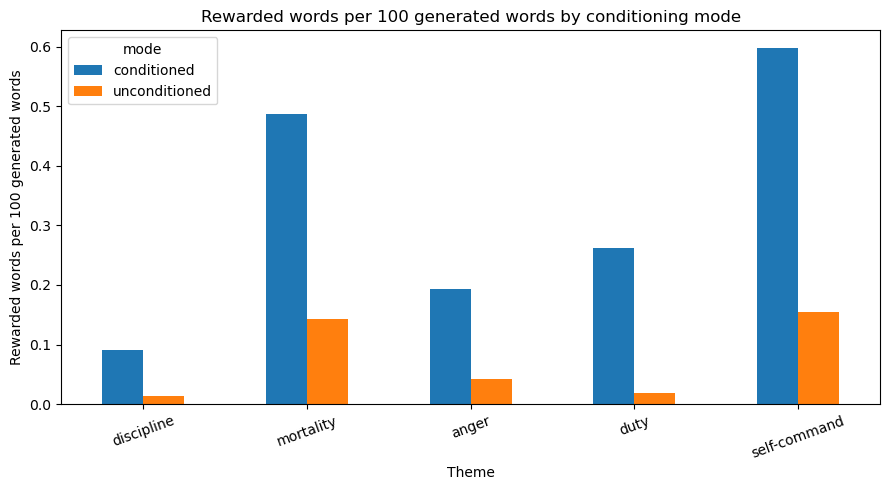

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW7.2\result images\hw7_2\task5_reward_word_rate.png


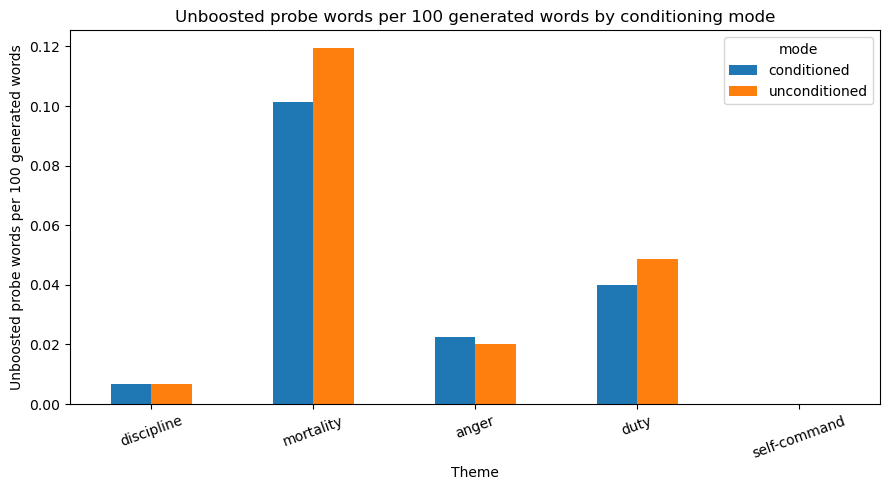

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW7.2\result images\hw7_2\task5_probe_word_rate.png


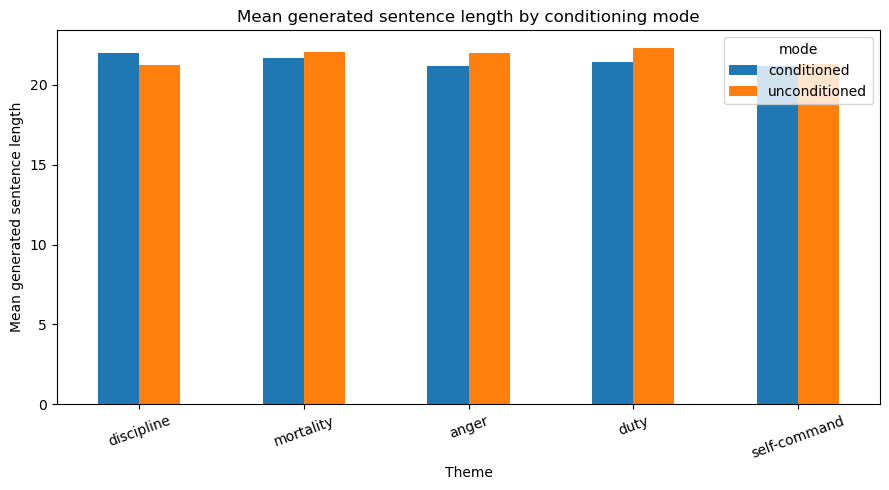

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW7.2\result images\hw7_2\task5_sentence_length.png


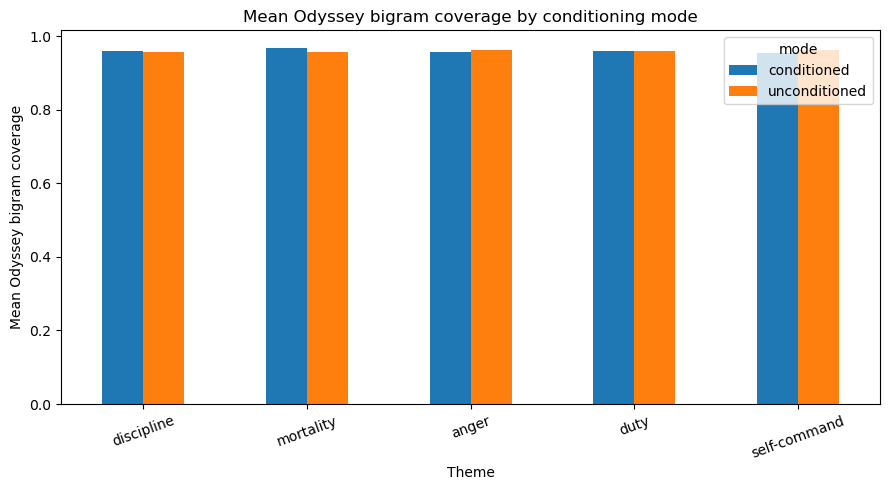

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW7.2\result images\hw7_2\task5_bigram_coverage.png


In [5]:
for metric, ylabel, filename in [
    (
        "reward_rate_per_100_words",
        "Rewarded words per 100 generated words",
        "task5_reward_word_rate.png",
    ),
    (
        "probe_rate_per_100_words",
        "Unboosted probe words per 100 generated words",
        "task5_probe_word_rate.png",
    ),
    (
        "length",
        "Mean generated sentence length",
        "task5_sentence_length.png",
    ),
    (
        "odyssey_bigram_coverage",
        "Mean Odyssey bigram coverage",
        "task5_bigram_coverage.png",
    ),
]:
    grouped = (
        metrics.groupby(
            [
                "theme",
                "mode",
            ]
        )[metric]
        .mean()
        .unstack(
            "mode"
        )
        .reindex(
            THEMES
        )
    )

    grouped.plot(
        kind="bar",
        figsize=(9, 5),
    )

    plt.xlabel("Theme")
    plt.ylabel(ylabel)
    plt.title(
        ylabel
        + " by conditioning mode"
    )
    plt.xticks(rotation=20)
    plt.tight_layout()

    path = (
        RESULT_DIR
        / filename
    )

    plt.savefig(
        path,
        dpi=200,
    )

    plt.show()

    print("Saved:", path.resolve())

## Interpretation rule

A rise in the rewarded-word rate is expected by construction. It demonstrates that the conditioning mechanism is operating, but it is not by itself evidence that the Marcus passage's meaning was preserved.

The unboosted probe rate is a separate lexical check. The broad Jensen-Shannon distance is interpreted only relative to the finite-sample null benchmark computed from unconditioned groups.

For the anger condition in particular, increasing words such as `anger`, `wrath`, or `rage` could move the output away from a Marcus passage that counsels restraint.

Task 6 treats semantic and fluency failures as results rather than hiding them.

# Task 5 Conclusion

Conditioning measurably increased the explicitly rewarded vocabulary for every theme. The mean increases in rewarded words per 100 generated words were approximately:

- discipline: 0.078;
- mortality: 0.343;
- anger: 0.151;
- duty: 0.244;
- self-command: 0.443.

All five 95 percent bootstrap intervals for these rewarded-word differences were above zero. This is expected because the conditioning rule directly multiplies the probability of rewarded words.

The unboosted probe-word results are different. Every probe-word bootstrap interval includes zero, so this experiment does not show a reliable increase in unboosted thematic vocabulary. The self-command probe rate was zero in both modes for the two probe words that occur in the Odyssey vocabulary.

The raw conditioned-versus-unconditioned Jensen-Shannon distances were about 0.341 to 0.344. However, pairwise distances between independent unconditioned groups from the same base generator ranged from about 0.336 to 0.345, with mean about 0.341. Therefore the raw broad-vocabulary distance is dominated by finite-sample variation at this sample size and vocabulary size; it is not independent evidence of a global lexical shift.

The supported conclusion is narrow but clear: the fixed conditioning rule successfully changes the probability of the words it explicitly rewards. The present experiment does not establish preservation of the Marcus proposition or a broader semantic shift.